EDA
Importo las bibliotecas necesarias para la exploración

In [1]:
# Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path 
import duckdb

# Configuración estética general de las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13

# Evita que pandas trunque columnas al visualizar
pd.set_option("display.max_columns", None)

Lectura de la base de datos enriquecida, explora las clases de la variable objetivo "sii"

In [2]:
#leer el CSV
df_csv = pd.read_csv('df_eda_completo.csv')
df_csv['sii'].value_counts(dropna=False)

sii
0.0    1594
NaN    1224
1.0     730
2.0     378
3.0      34
Name: count, dtype: int64

Inicialmente solo se obtienen los datos tabulares de cuestionarios, sin embargo es importante integrar la informacion del acelerometro de muñeca, para ello se crearan nuevas columnas con los siguientes criterios a partir de las variables:
- enmo: representa movimiento total (en los ejes X,Y,Z).
- time_of_day: el registro del momento del dia de la informacion, es importante para separar actividades diurnas de trasnocho.
- anglez: el angulo en que se encuentra el dispositivo de la muñeca, sirve para detectar sueño vs actividad con celular en las noches.
- light: detecta luz, en el dia queremos actividad, en la noche nos sirve para detectar luz de pantallas.
- weekday: el dia se la semana de la medicion, queres discriminar dias escolares de fines de semana.
- quarter: corresponde al trimetre de las mediciones.

Usando estos datos generamos las siguientes columnas:
- enmo_general_semana: promedio de movimiento general todo el dia entre semana.
- enmo_general_fin_de_semana: promedio de movimiento general todo el dia en sabado y domingo.
- enmo_madrugada: promedio de movimiento en horas de la noche (12am a 5am), nuestro objetivo es detectar trasnocho.
- enmo_libre: promedio de actividad en horas libres (3pm que finaliza el horario escolar a 10pm)
- anglez_madrugada: cambios de la medicion en las horas que se esperan de sueño (esperamos poca actividad, muchos cambios de angulo sugieren uso de celular)
- light_dia: promedio de luz recibido en horas del dia (7am a 6pm)
- light_madrugada: promedio de luz entre 12am y 5am, sugiere exposicion a luz de pantalla en la madrugada.

Consideracion de estaciones: debido a que es poco probable que un participante use el dispositivo un año completo, no consideraremos inicialmente las estaciones. En caso que el analisis lo requiera mas adelante se incluira.

---
## Análisis exploratorio detallado
*Continuación del EDA a partir de la tabla integrada `df_eda_completo.csv` construida arriba.* A partir de aquí se estudia la variable objetivo, la fuga de información, los datos faltantes, la calidad de los datos y la relación de las variables físicas, de sueño y del acelerómetro con `sii`, controlando el efecto de la edad.

> El EDA es descriptivo: las asociaciones **no son causas** y el objetivo es orientar el modelado, no diagnosticar.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

df = pd.read_csv("df_eda_completo.csv")
print("Filas y columnas:", df.shape)
print("IDs únicos:", df["id"].nunique())
print(df.dtypes.value_counts().to_string())


Filas y columnas: (3960, 89)
IDs únicos: 3960
float64    75
str        12
int64       2


## 1. Variable objetivo: `sii`
`sii` (Severity Impairment Index) toma cuatro niveles: 0 = ninguno, 1 = leve, 2 = moderado, 3 = severo. Se deriva del puntaje total del cuestionario PCIAT.


Registros totales: 3960
Sin etiqueta (sii vacío): 1224 (30.9%)
Con etiqueta: 2736 (69.1%)


,n,porcentaje
sii,,
0,1594,58.3
1,730,26.7
2,378,13.8
3,34,1.2


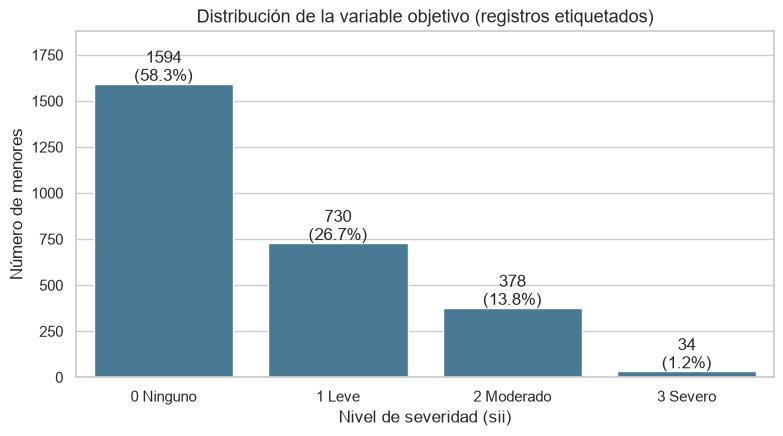

In [4]:
n_total = len(df)
n_sin = df["sii"].isna().sum()
print(f"Registros totales: {n_total}")
print(f"Sin etiqueta (sii vacío): {n_sin} ({n_sin/n_total:.1%})")
print(f"Con etiqueta: {n_total-n_sin} ({1-n_sin/n_total:.1%})")

lab = df[df["sii"].notna()].copy()
lab["sii"] = lab["sii"].astype(int)
conteo = lab["sii"].value_counts().sort_index()
tabla = pd.DataFrame({"n": conteo, "porcentaje": (conteo / conteo.sum() * 100).round(1)})
tabla.index.name = "sii"
display(tabla)

fig, ax = plt.subplots()
sns.barplot(x=conteo.index, y=conteo.values, color="#3b7ea1", ax=ax)
for i, v in enumerate(conteo.values):
    ax.text(i, v + 15, f"{v}\n({v/conteo.sum():.1%})", ha="center")
ax.set_xticks(range(4))
ax.set_xticklabels(["0 Ninguno", "1 Leve", "2 Moderado", "3 Severo"])
ax.set_xlabel("Nivel de severidad (sii)")
ax.set_ylabel("Número de menores")
ax.set_title("Distribución de la variable objetivo (registros etiquetados)")
ax.set_ylim(0, conteo.max() * 1.18)
plt.show()


**Lectura.** Las clases están muy desbalanceadas: cerca del 58 % está en el nivel 0 y el nivel 3 (severo) tiene apenas 34 casos (1,2 %). Un modelo que siempre prediga "0" acertaría alrededor del 58 %, así que **la exactitud (accuracy) no sirve como métrica principal** y el nivel 3 será muy difícil de aprender y de evaluar. Además, 1.224 registros (31 %) no tienen etiqueta y no se pueden usar para entrenar un modelo supervisado.

## 2. Fuga de información: `sii` se calcula a partir del PCIAT
Si el target se obtiene de unas columnas, esas columnas no pueden ser predictoras. Se comprueba la relación entre `PCIAT-PCIAT_Total` y `sii`.


Columnas PCIAT (22): ['PCIAT-Season', 'PCIAT-PCIAT_01', 'PCIAT-PCIAT_02'] ... ['PCIAT-PCIAT_20', 'PCIAT-PCIAT_Total']


,min,max,count
sii,,,
0,0.0,30.0,1594
1,31.0,49.0,730
2,50.0,79.0,378
3,80.0,93.0,34


¿PCIAT_Total está vacío exactamente cuando sii está vacío? True


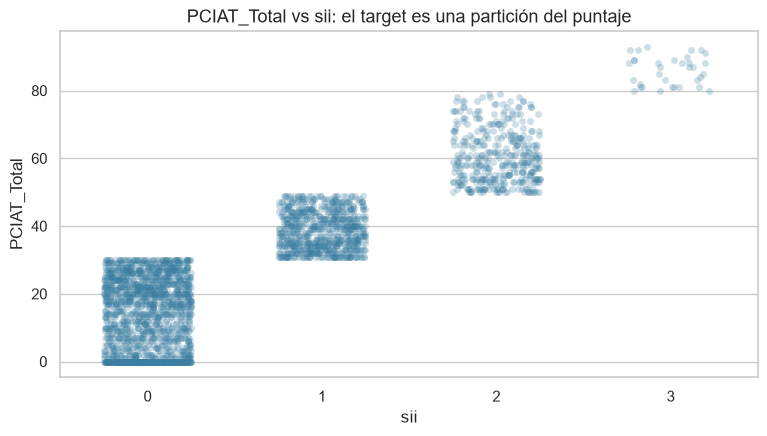

In [5]:
pciat = [c for c in df.columns if c.startswith("PCIAT")]
print(f"Columnas PCIAT ({len(pciat)}):", pciat[:3], "...", pciat[-2:])

rangos = lab.groupby("sii")["PCIAT-PCIAT_Total"].agg(["min", "max", "count"])
display(rangos)

coincide = ((df["PCIAT-PCIAT_Total"].isna()) == (df["sii"].isna())).all()
print("¿PCIAT_Total está vacío exactamente cuando sii está vacío?", coincide)

fig, ax = plt.subplots()
sns.stripplot(data=lab, x="sii", y="PCIAT-PCIAT_Total", alpha=0.25, jitter=0.25, ax=ax, color="#3b7ea1")
ax.set_title("PCIAT_Total vs sii: el target es una partición del puntaje")
ax.set_xlabel("sii")
ax.set_ylabel("PCIAT_Total")
plt.show()


**Lectura.** Los niveles de `sii` corresponden a rangos exactos de `PCIAT_Total`: 0 a 30 (ninguno), 31 a 49 (leve), 50 a 79 (moderado) y 80 o más (severo). Por lo tanto **las 22 columnas PCIAT (los 20 ítems, el total y la temporada) deben excluirse de los predictores**; incluirlas daría un modelo "perfecto" pero inútil, porque en la práctica ese cuestionario es justo lo que se quiere evitar aplicar.

## 3. Edad y sexo


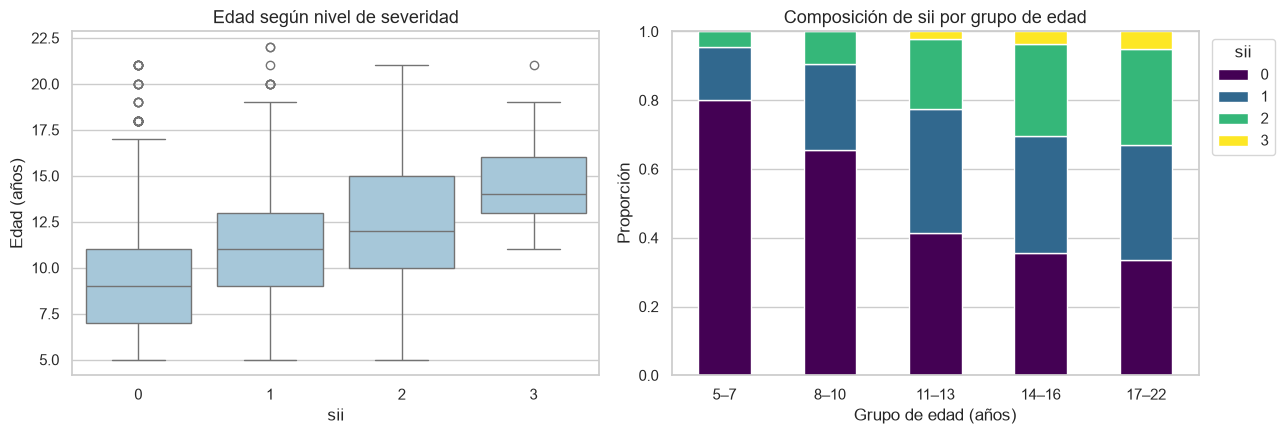

,count,mean,std,min,25%,50%,75%,max
sii,,,,,,,,
0,1594.0,9.25,3.13,5.0,7.0,9.0,11.0,21.0
1,730.0,11.12,3.30,5.0,9.0,11.0,13.0,22.0
2,378.0,12.29,3.28,5.0,10.0,12.0,15.0,21.0
3,34.0,14.68,2.38,11.0,13.0,14.0,16.0,21.0


Correlación de Spearman edad–sii: 0.379


sii,0,1,2,3
Basic_Demos-Sex,,,,
0,956,481,276,26
1,638,249,102,8


sii,0,1,2,3
Basic_Demos-Sex,,,,
0,55.0,27.7,15.9,1.5
1,64.0,25.0,10.2,0.8


Chi-cuadrado sexo vs sii: chi2=27.6, p=4.4e-06


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=lab, x="sii", y="Basic_Demos-Age", color="#9ecae1", ax=axes[0])
axes[0].set_title("Edad según nivel de severidad")
axes[0].set_xlabel("sii")
axes[0].set_ylabel("Edad (años)")

lab["grupo_edad"] = pd.cut(lab["Basic_Demos-Age"], [4, 7, 10, 13, 16, 23],
                           labels=["5–7", "8–10", "11–13", "14–16", "17–22"])
prop = pd.crosstab(lab["grupo_edad"], lab["sii"], normalize="index")
prop.plot(kind="bar", stacked=True, colormap="viridis", ax=axes[1], rot=0)
axes[1].set_title("Composición de sii por grupo de edad")
axes[1].set_xlabel("Grupo de edad (años)")
axes[1].set_ylabel("Proporción")
axes[1].legend(title="sii", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(lab.groupby("sii")["Basic_Demos-Age"].describe().round(2))
print("Correlación de Spearman edad–sii:", round(stats.spearmanr(lab["Basic_Demos-Age"], lab["sii"])[0], 3))

sexo = pd.crosstab(lab["Basic_Demos-Sex"], lab["sii"])
display(sexo)
display((pd.crosstab(lab["Basic_Demos-Sex"], lab["sii"], normalize="index") * 100).round(1))
chi2, p, _, _ = stats.chi2_contingency(sexo)
print(f"Chi-cuadrado sexo vs sii: chi2={chi2:.1f}, p={p:.2g}")


**Lectura.**
- **La edad es la variable más asociada con `sii`** (Spearman ≈ 0,38): entre los 5 y 7 años el 80 % está en el nivel 0, y de los 14 años en adelante cerca de un tercio está en el nivel 2 o 3. Esto es un **factor de confusión**: muchas variables físicas (estatura, peso, masa muscular) crecen con la edad y parecerán asociadas con `sii` solo por eso. En la sección 8 se controla este efecto.
- La proporción de niveles moderado y severo es distinta por sexo y la diferencia es estadísticamente significativa (la columna viene codificada 0/1; verificar el significado de cada código en el diccionario de datos de la competencia). Cualquier análisis de sesgo debe revisar sexo y edad por separado.

## 4. Valores faltantes


Variables candidatas a predictor: 65
Sin ningún faltante: 3
Con más del 50 % faltante: 20
Con más del 75 % faltante: 10


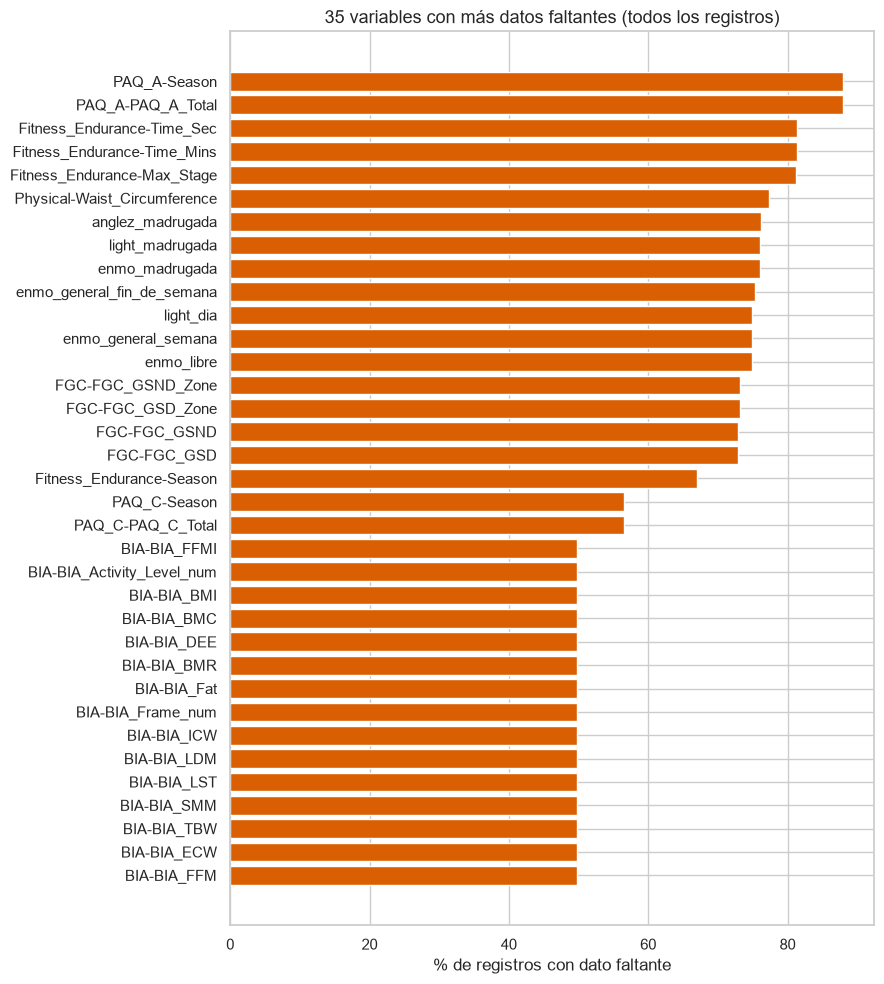

In [7]:
feat = [c for c in df.columns if c not in ["id", "sii"] and not c.startswith("PCIAT")]
falt = df[feat].isna().mean().sort_values(ascending=False)
print(f"Variables candidatas a predictor: {len(feat)}")
print(f"Sin ningún faltante: {(falt == 0).sum()}")
print(f"Con más del 50 % faltante: {(falt > 0.5).sum()}")
print(f"Con más del 75 % faltante: {(falt > 0.75).sum()}")

fig, ax = plt.subplots(figsize=(9, 10))
top = falt.head(35)[::-1]
ax.barh(top.index, top.values * 100, color="#d95f02")
ax.set_xlabel("% de registros con dato faltante")
ax.set_title("35 variables con más datos faltantes (todos los registros)")
plt.tight_layout()
plt.show()


### 4.1 Los faltantes no son aleatorios: dependen de la edad y del instrumento
Varias mediciones solo se aplican a ciertos rangos de edad (por ejemplo, el cuestionario de actividad física para niños y el de adolescentes). Se mide qué fracción de registros etiquetados tiene cada bloque de variables, por grupo de edad.


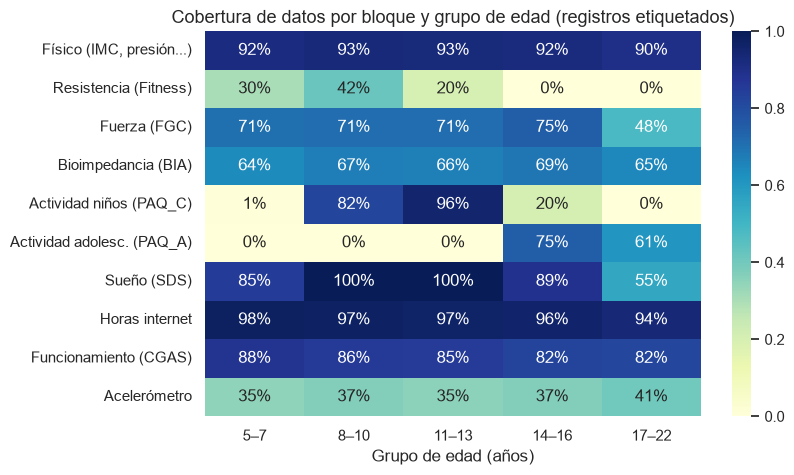

sii,sii 0,sii 1,sii 2,sii 3
bloque,,,,
"Físico (IMC, presión...)",92,93,93,97
Resistencia (Fitness),30,25,18,6
Fuerza (FGC),72,67,67,71
Bioimpedancia (BIA),67,66,65,71
Actividad niños (PAQ_C),48,61,57,50
Actividad adolesc. (PAQ_A),8,16,26,38
Sueño (SDS),92,93,91,88
Horas internet,97,98,96,100
Funcionamiento (CGAS),85,87,85,85


In [8]:
bloques = {
    "Físico (IMC, presión...)": "Physical-BMI",
    "Resistencia (Fitness)": "Fitness_Endurance-Time_Mins",
    "Fuerza (FGC)": "FGC-FGC_CU",
    "Bioimpedancia (BIA)": "BIA-BIA_BMI",
    "Actividad niños (PAQ_C)": "PAQ_C-PAQ_C_Total",
    "Actividad adolesc. (PAQ_A)": "PAQ_A-PAQ_A_Total",
    "Sueño (SDS)": "SDS-SDS_Total_T",
    "Horas internet": "PreInt_EduHx-computerinternet_hoursday",
    "Funcionamiento (CGAS)": "CGAS-CGAS_Score",
    "Acelerómetro": "enmo_general_semana",
}
cobertura = pd.DataFrame({k: lab.groupby("grupo_edad", observed=True)[v].apply(lambda s: s.notna().mean())
                          for k, v in bloques.items()}).T
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(cobertura, annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set_xlabel("Grupo de edad (años)")
ax.set_title("Cobertura de datos por bloque y grupo de edad (registros etiquetados)")
plt.show()

cob_sii = pd.DataFrame({k: lab.groupby("sii")[v].apply(lambda s: s.notna().mean()) for k, v in bloques.items()}).T
display((cob_sii * 100).round(0).astype(int).rename_axis("bloque").add_prefix("sii "))


**Lectura.**
- El cuestionario de actividad para niños (PAQ_C) solo existe entre los 8 y 13 años, y el de adolescentes (PAQ_A) casi solo desde los 14: son **faltantes estructurales** y por eso cada uno tiene un porcentaje alto de vacíos. No se pueden imputar con la media sin perder esa información; conviene usar indicadores de "dato ausente" o modelos que acepten vacíos.
- **La prueba de resistencia física** (Fitness Endurance) solo se aplicó a menores de 14 años (0 % de cobertura desde esa edad) y está presente en el 30 % de los casos del nivel 0 y solo en el 6 % del nivel 3, y el **acelerómetro** en el 37 % del nivel 0 frente al 29 % del nivel 3. Es decir, la **ausencia de la medición está relacionada con el target**, un posible sesgo de selección que hay que tener en cuenta al comparar modelos.
- El acelerómetro cubre solo 996 registros (25 % del total), todos con etiqueta. Si se exige acelerómetro, la muestra baja a menos de mil menores y el nivel 3 queda con 10 casos.

## 5. Calidad de los datos: valores anómalos y duplicados


CGAS máximo: 999.0 | registros con CGAS > 100: 1
Physical-BMI: valores iguales a 0 = 7
Physical-Weight: valores iguales a 0 = 61
Physical-Diastolic_BP: valores iguales a 0 = 1
Physical-Systolic_BP: valores iguales a 0 = 1
¿IMC reportado ≈ 703·peso/estatura²? (estatura en pulgadas, peso en libras): 100.0% de los casos


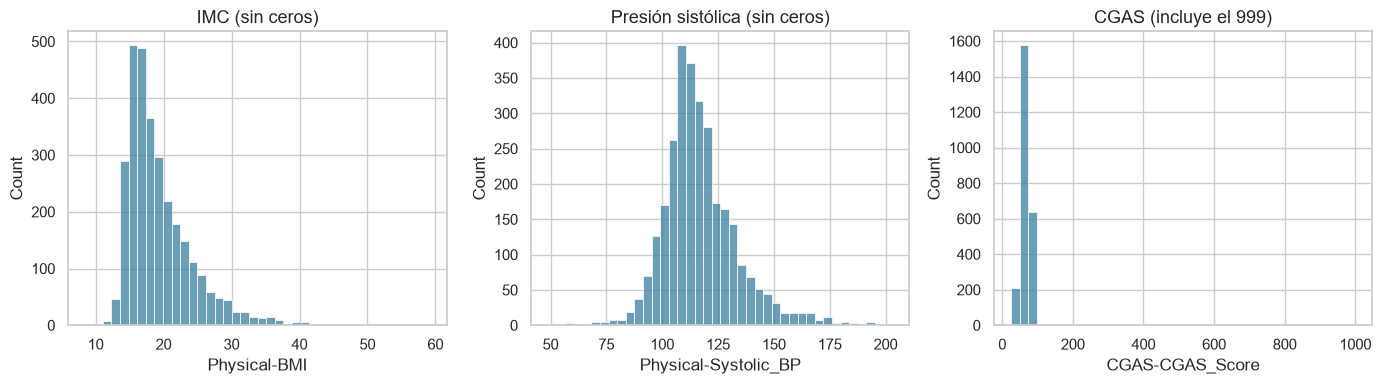


Filas idénticas en todas las columnas excepto id: 190
Promedio de columnas con dato en esas filas: 3.2
Etiquetadas entre ellas: 0
Registros con más del 70 % de las variables candidatas vacías: 1088 (etiquetados: 300)


In [9]:
print("CGAS máximo:", df["CGAS-CGAS_Score"].max(), "| registros con CGAS > 100:", (df["CGAS-CGAS_Score"] > 100).sum())
for c in ["Physical-BMI", "Physical-Weight", "Physical-Diastolic_BP", "Physical-Systolic_BP"]:
    print(f"{c}: valores iguales a 0 = {(df[c] == 0).sum()}")

rev = df[["Physical-Height", "Physical-Weight", "Physical-BMI"]].dropna()
rev = rev[(rev > 0).all(axis=1)]
imc_pulg_lb = 703 * rev["Physical-Weight"] / rev["Physical-Height"] ** 2
print("¿IMC reportado ≈ 703·peso/estatura²? (estatura en pulgadas, peso en libras):",
      f"{(np.abs(imc_pulg_lb - rev['Physical-BMI']) < 1).mean():.1%} de los casos")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df["Physical-BMI"][df["Physical-BMI"] > 0], bins=40, ax=axes[0], color="#3b7ea1")
axes[0].set_title("IMC (sin ceros)")
sns.histplot(df["Physical-Systolic_BP"][df["Physical-Systolic_BP"] > 0], bins=40, ax=axes[1], color="#3b7ea1")
axes[1].set_title("Presión sistólica (sin ceros)")
sns.histplot(df["CGAS-CGAS_Score"], bins=40, ax=axes[2], color="#3b7ea1")
axes[2].set_title("CGAS (incluye el 999)")
plt.tight_layout()
plt.show()

dup_mask = df.drop(columns="id").duplicated(keep=False)
dup = df[dup_mask]
print(f"\nFilas idénticas en todas las columnas excepto id: {dup_mask.sum()}")
print("Promedio de columnas con dato en esas filas:", dup.drop(columns="id").notna().sum(axis=1).mean().round(1))
print("Etiquetadas entre ellas:", dup["sii"].notna().sum())

sin_info = (df[feat].isna().mean(axis=1) > 0.7)
print(f"Registros con más del 70 % de las variables candidatas vacías: {sin_info.sum()} (etiquetados: {df.loc[sin_info,'sii'].notna().sum()})")


**Lectura.**
- Hay códigos de dato faltante disfrazados de valores: un CGAS de 999, y ceros en IMC, peso y presión arterial. Deben convertirse en `NaN` antes de calcular estadísticos o entrenar.
- Las filas "duplicadas" (190) no son personas repetidas: son registros casi vacíos (solo tienen unas 3 columnas con dato) y ninguno tiene etiqueta, así que salen solos al filtrar por `sii`. Aparte, hay 300 registros etiquetados con más del 70 % de las variables vacías; conviene decidir si se conservan.
- Estatura y peso están en pulgadas y libras (el IMC reportado coincide con la fórmula en unidades inglesas); conviene convertirlos si se van a interpretar o comparar con tablas externas.

## 6. Variables físicas y de aptitud


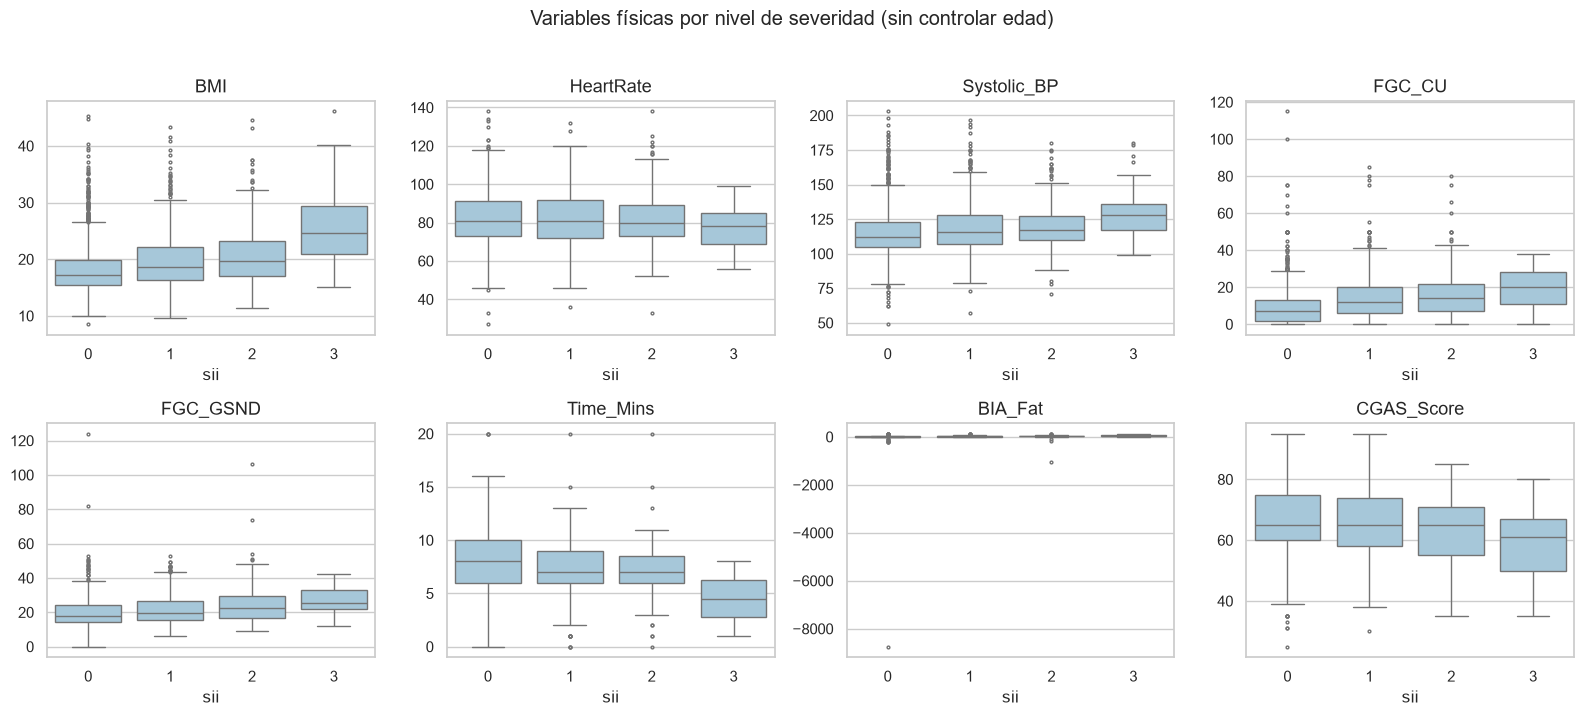

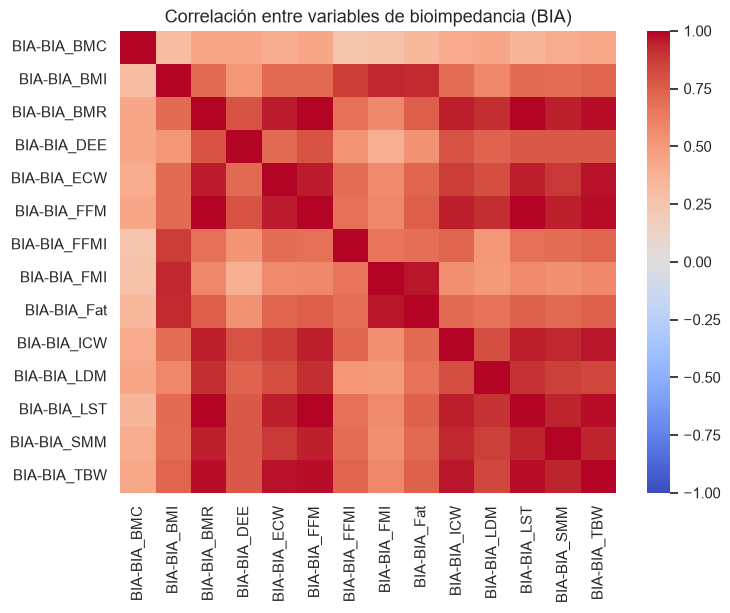

Pares de variables BIA con |ρ| > 0,95: 14 de 91


In [10]:
lab_q = lab.copy()
for c, bad in [("CGAS-CGAS_Score", lambda s: s > 100),
               ("Physical-BMI", lambda s: s <= 0), ("Physical-Weight", lambda s: s <= 0),
               ("Physical-Diastolic_BP", lambda s: s <= 0), ("Physical-Systolic_BP", lambda s: s <= 0)]:
    lab_q.loc[bad(lab_q[c]), c] = np.nan

vars_fis = ["Physical-BMI", "Physical-HeartRate", "Physical-Systolic_BP", "FGC-FGC_CU",
            "FGC-FGC_GSND", "Fitness_Endurance-Time_Mins", "BIA-BIA_Fat", "CGAS-CGAS_Score"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), vars_fis):
    sns.boxplot(data=lab_q, x="sii", y=c, color="#9ecae1", ax=ax, fliersize=2)
    ax.set_title(c.split("-")[-1])
    ax.set_xlabel("sii")
    ax.set_ylabel("")
plt.suptitle("Variables físicas por nivel de severidad (sin controlar edad)", y=1.02)
plt.tight_layout()
plt.show()

bia = [c for c in df.columns if c.startswith("BIA-") and "Season" not in c and "num" not in c]
cm = lab_q[bia].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación entre variables de bioimpedancia (BIA)")
plt.show()
pares = (cm.abs().where(np.triu(np.ones(cm.shape), 1).astype(bool)) > 0.95).sum().sum()
print(f"Pares de variables BIA con |ρ| > 0,95: {pares} de {len(bia)*(len(bia)-1)//2}")


**Lectura.** A simple vista muchas variables físicas crecen con la severidad, pero eso en buena parte es la edad (ver sección 8). Las variables de bioimpedancia están **altamente correlacionadas entre sí** (redundantes): usarlas todas aporta poca información nueva y puede inestabilizar modelos lineales. Conviene escoger unas pocas o reducir dimensión.

## 7. Sueño y uso de internet
`SDS` es la escala de trastornos del sueño (puntaje T; a más alto, más problemas de sueño). `computerinternet_hoursday` es una categoría de horas diarias frente a una pantalla (0 a 3), reportada por el propio participante o su familia.


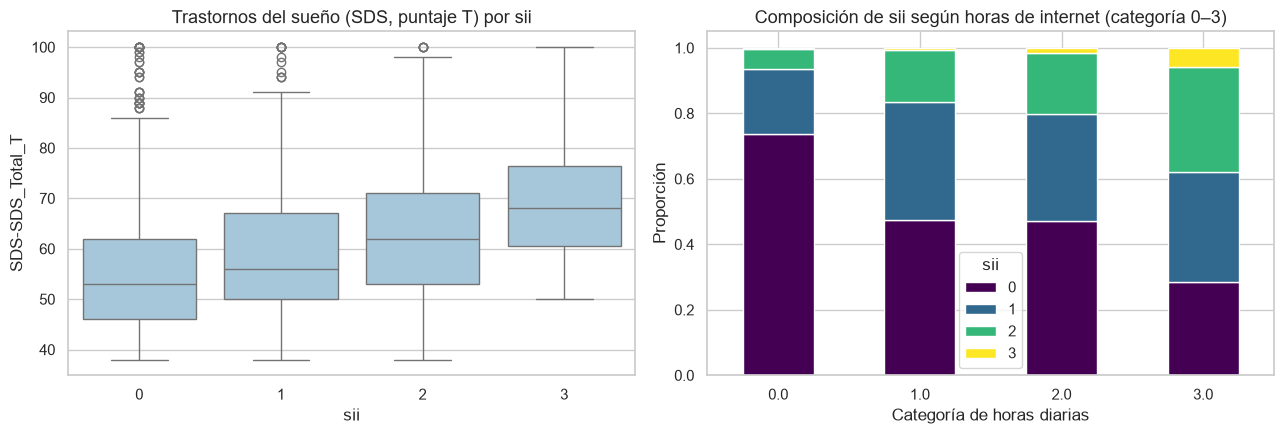

PreInt_EduHx-computerinternet_hoursday
0.0    1268
1.0     340
2.0     784
3.0     262
NaN      82


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=lab_q, x="sii", y="SDS-SDS_Total_T", color="#9ecae1", ax=axes[0])
axes[0].set_title("Trastornos del sueño (SDS, puntaje T) por sii")
prop = pd.crosstab(lab_q["PreInt_EduHx-computerinternet_hoursday"], lab_q["sii"], normalize="index")
prop.plot(kind="bar", stacked=True, colormap="viridis", ax=axes[1], rot=0)
axes[1].set_title("Composición de sii según horas de internet (categoría 0–3)")
axes[1].set_xlabel("Categoría de horas diarias")
axes[1].set_ylabel("Proporción")
plt.tight_layout()
plt.show()
print(lab_q["PreInt_EduHx-computerinternet_hoursday"].value_counts(dropna=False).sort_index().to_string())


**Lectura.** Quienes tienen mayor severidad reportan más problemas de sueño y más horas de pantalla. La relación con el sueño es coherente con la literatura revisada en el estado del arte (Yu et al., 2026). **Cuidado con la variable de horas de internet**: está muy cerca del propio constructo que se quiere predecir (es un autoinforme de uso) y no es una medida física fácil de obtener; el equipo debe decidir si entra como predictor o se deja fuera para ser coherente con el objetivo de "usar solo indicadores físicos y de sueño".

## 8. Acelerómetro de muñeca
Resumen por menor de los registros del reloj (solo cuando lo llevaba puesto): `enmo` es el movimiento, `anglez` el ángulo de la muñeca y `light` la luz ambiente; "madrugada" son las horas de 12 a. m. a 5 a. m. y "libre" las de 3 p. m. a 10 p. m.


Menores con acelerómetro: 996 de 3960


enmo_general_semana        enmo_general_fin_de_semana        enmo_libre        enmo_madrugada        light_dia         light_madrugada         \
                  count median                      count median      count median          count median     count  median           count median   
sii                                                                                                                                                 
0                   583  0.046                        572  0.041        583  0.057            556  0.009       583  41.418             556  9.512   
1                   266  0.038                        262  0.032        266  0.046            255  0.008       266  38.899             255  9.709   
2                   137  0.033                        133  0.028        137  0.039            131  0.008       137  33.218             131  9.786   
3                    10  0.023                         10  0.024         10  0.027              9  0.006        10  31.256               9  8.556   

    anglez_madrugada          
               count  median  
sii                           
0                550  44.751  
1                253  43.738  
2                131  44.616  
3                  9  41.943

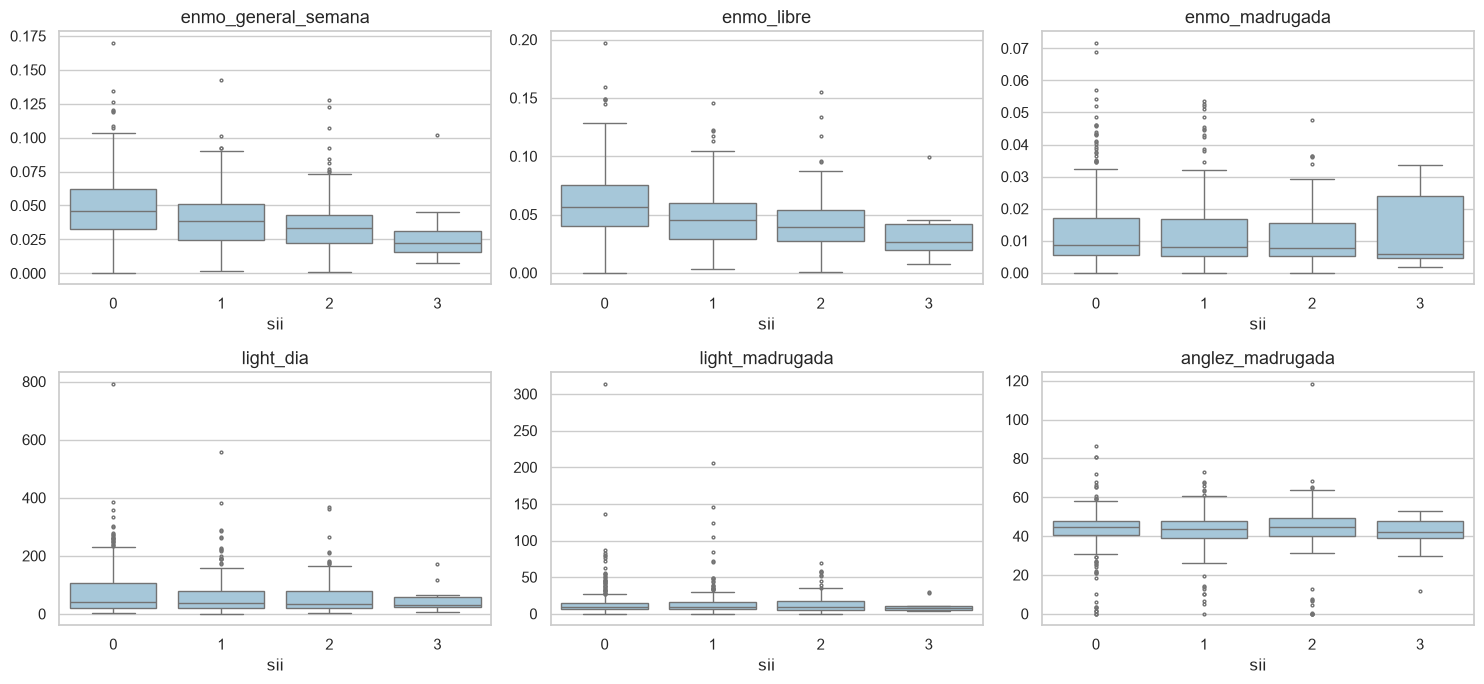

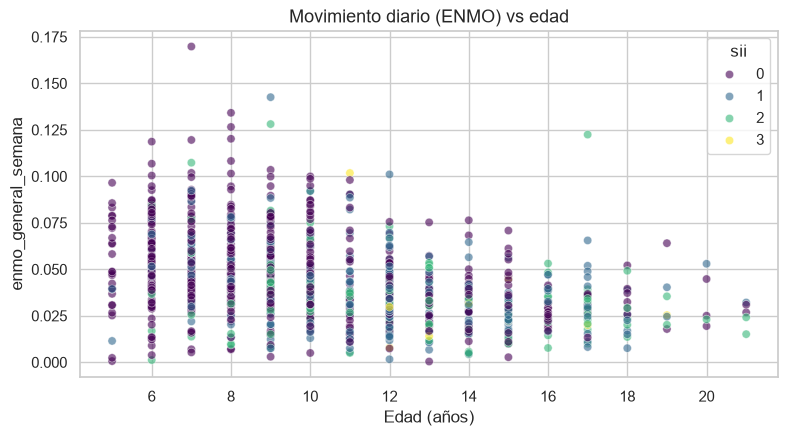

In [12]:
acc = ["enmo_general_semana", "enmo_general_fin_de_semana", "enmo_libre", "enmo_madrugada",
       "light_dia", "light_madrugada", "anglez_madrugada"]
print(f"Menores con acelerómetro: {df['enmo_general_semana'].notna().sum()} de {len(df)}")
display(lab.groupby("sii")[acc].agg(["count", "median"]).round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), ["enmo_general_semana", "enmo_libre", "enmo_madrugada",
                                "light_dia", "light_madrugada", "anglez_madrugada"]):
    sns.boxplot(data=lab, x="sii", y=c, color="#9ecae1", ax=ax, fliersize=2)
    ax.set_title(c)
    ax.set_xlabel("sii")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
sns.scatterplot(data=lab, x="Basic_Demos-Age", y="enmo_general_semana", hue="sii", palette="viridis", alpha=0.6, ax=ax)
ax.set_title("Movimiento diario (ENMO) vs edad")
ax.set_xlabel("Edad (años)")
plt.show()


**Lectura.** El movimiento medio (ENMO) baja a medida que sube la severidad, pero **también baja con la edad**, así que no se puede atribuir solo al uso de internet. Las variables de luz tienen colas muy largas (valores extremos), por lo que conviene transformarlas (logaritmo) o usar modelos robustos.

## 9. Asociación con `sii`: sin controlar y controlando la edad
Para cada variable numérica (excluyendo PCIAT) se calcula la correlación de Spearman con `sii` y la correlación parcial que **elimina el efecto lineal de la edad** (sobre rangos). Si una variable pierde fuerza al controlar por edad, su asociación aparente se explicaba por la edad.


,variable,n,rho_sin_controlar,rho_controlando_edad
0,SDS-SDS_Total_Raw,2527,0.231,0.239
1,SDS-SDS_Total_T,2525,0.230,0.238
2,PreInt_EduHx-computerinternet_hoursday,2654,0.335,0.211
3,Basic_Demos-Sex,2736,-0.097,-0.126
4,enmo_libre,996,-0.264,-0.116
5,enmo_general_semana,996,-0.256,-0.116
6,enmo_general_fin_de_semana,977,-0.239,-0.105
7,Fitness_Endurance-Max_Stage,731,-0.079,-0.095
8,Fitness_Endurance-Time_Mins,728,-0.075,-0.089
9,BIA-BIA_ICW,1813,0.360,0.089


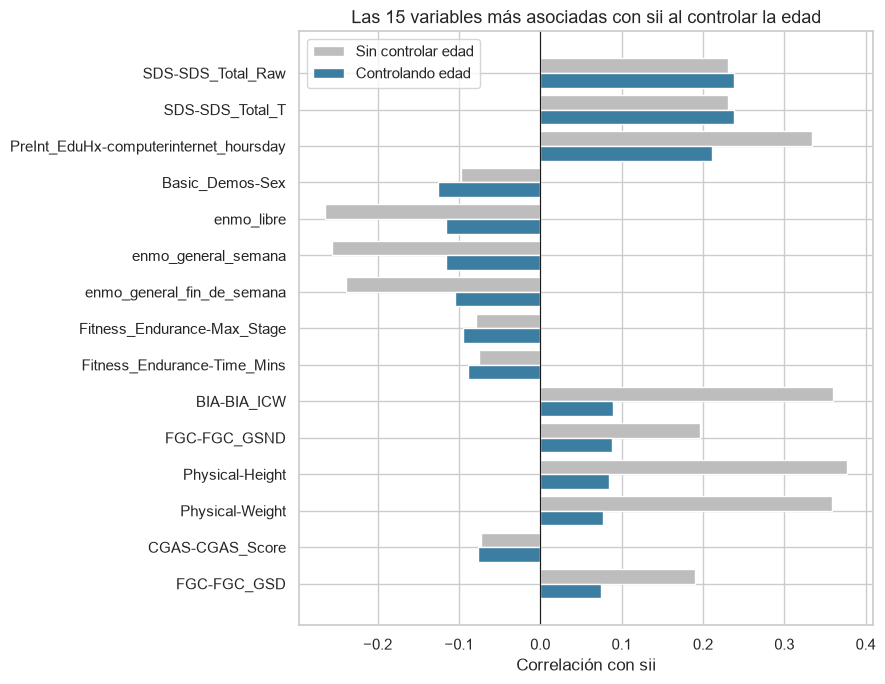

In [13]:
def parcial_edad(col):
    s = lab_q[[col, "sii", "Basic_Demos-Age"]].dropna()
    if len(s) < 300 or s[col].nunique() < 2:
        return None
    r = s.rank()
    ra = r["Basic_Demos-Age"].values
    def resid(y):
        b = np.polyfit(ra, y, 1)
        return y - np.polyval(b, ra)
    rho = stats.spearmanr(s[col], s["sii"])[0]
    rho_p = stats.pearsonr(resid(r[col].values), resid(r["sii"].values))[0]
    return len(s), rho, rho_p

filas = []
for c in lab_q.select_dtypes("number").columns:
    if c in ("sii", "Basic_Demos-Age") or c.startswith("PCIAT"):
        continue
    out = parcial_edad(c)
    if out:
        filas.append((c, *out))
assoc = pd.DataFrame(filas, columns=["variable", "n", "rho_sin_controlar", "rho_controlando_edad"])
top = assoc.reindex(assoc["rho_controlando_edad"].abs().sort_values(ascending=False).index).head(15)
display(top.round(3).reset_index(drop=True))

orden = top.iloc[::-1]
y = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(y + 0.2, orden["rho_sin_controlar"], height=0.4, label="Sin controlar edad", color="#bdbdbd")
ax.barh(y - 0.2, orden["rho_controlando_edad"], height=0.4, label="Controlando edad", color="#3b7ea1")
ax.set_yticks(y)
ax.set_yticklabels(orden["variable"])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Correlación con sii")
ax.set_title("Las 15 variables más asociadas con sii al controlar la edad")
ax.legend()
plt.tight_layout()
plt.show()


**Lectura.**
- Al quitar el efecto de la edad, las variables antropométricas y de composición corporal (estatura, peso, masa magra, bioimpedancia) **pierden casi toda su fuerza**: eran un reflejo de la edad.
- Lo que se mantiene son señales de **sueño** (SDS, ρ parcial ≈ 0,24), de **horas de pantalla** (≈ 0,21, con la advertencia de la sección 7), de **sexo** (≈ −0,13) y de **actividad medida con el reloj** (ENMO, ≈ −0,12). Las mediciones de aptitud (resistencia, fuerza de agarre) son más débiles (|ρ| ≈ 0,1).
- Todas las asociaciones son **débiles a moderadas**. Esto anticipa que un modelo basado solo en mediciones físicas y de sueño tendrá un desempeño limitado, algo coherente con el AUC moderado (0,72) del modelo de Yu et al. (2026).

### 9.1 ¿Aportan más las variables de madrugada que las de día?
Las variables del reloj se diseñaron con la hipótesis de que la actividad y la luz en la madrugada (12 a. m. a 5 a. m.) delatan trasnocho y uso de pantallas. Se compara su asociación con `sii`, controlando por edad, frente a las variables de día.

,variable,momento,n,rho_sin_controlar,rho_controlando_edad,p_valor_aprox
0,enmo_general_semana,día / general,996,-0.256,-0.116,0.000
1,enmo_general_fin_de_semana,día / general,977,-0.239,-0.105,0.001
2,enmo_libre,día / general,996,-0.264,-0.116,0.000
3,enmo_madrugada,madrugada,951,-0.030,-0.047,0.146
4,light_dia,día / general,996,-0.080,-0.063,0.046
5,light_madrugada,madrugada,951,0.016,-0.021,0.511
6,anglez_madrugada,madrugada,943,-0.024,0.030,0.356


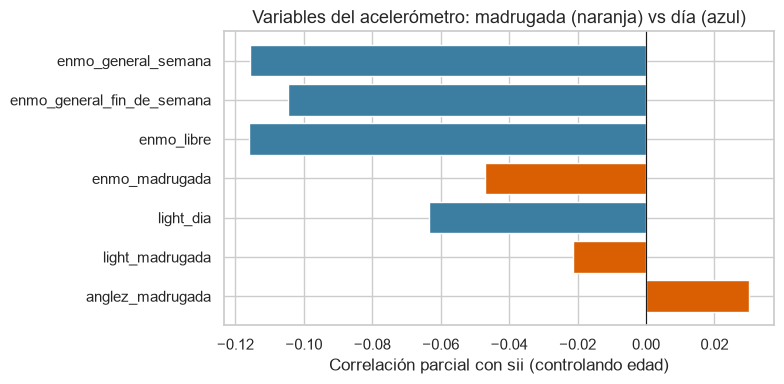

In [14]:
acc_cols = ["enmo_general_semana", "enmo_general_fin_de_semana", "enmo_libre", "enmo_madrugada",
            "light_dia", "light_madrugada", "anglez_madrugada"]
filas = []
for c in acc_cols:
    s = lab_q[[c, "sii", "Basic_Demos-Age"]].dropna()
    r = s.rank()
    ra = r["Basic_Demos-Age"].values
    res = lambda y: y - np.polyval(np.polyfit(ra, y, 1), ra)
    rho = stats.spearmanr(s[c], s["sii"])[0]
    rp, p = stats.pearsonr(res(r[c].values), res(r["sii"].values))
    filas.append((c, "madrugada" if ("madrugada" in c) else "día / general", len(s), rho, rp, p))
tabla_acc = pd.DataFrame(filas, columns=["variable", "momento", "n", "rho_sin_controlar",
                                         "rho_controlando_edad", "p_valor_aprox"])
display(tabla_acc.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
colores = tabla_acc["momento"].map({"madrugada": "#d95f02", "día / general": "#3b7ea1"})
ax.barh(tabla_acc["variable"][::-1], tabla_acc["rho_controlando_edad"][::-1], color=colores[::-1])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Correlación parcial con sii (controlando edad)")
ax.set_title("Variables del acelerómetro: madrugada (naranja) vs día (azul)")
plt.tight_layout()
plt.show()


**Lectura.** Las variables de **día y de movimiento general** (ENMO) conservan una asociación negativa con `sii` tras controlar la edad (≈ −0,11), mientras que las de **madrugada** (movimiento, luz y variación del ángulo) quedan cerca de cero (|ρ| < 0,05) y no se distinguen de cero con ~950 casos. Con estos datos, **la hipótesis de que la madrugada es más informativa no se sostiene**; lo que parece aportar es el nivel general de actividad durante el día. Puede ser por ruido (pocas horas de madrugada con reloj puesto) o porque el resumen por promedio pierde información, y por eso conviene probar otras formas de resumir esas horas antes de descartarlas.

## 10. Conclusiones y decisiones para el modelado

**Hallazgos principales**
1. **Desbalance fuerte:** 58 % / 27 % / 14 % / 1,2 % entre los niveles 0 a 3; el nivel 3 tiene solo 34 casos. El 31 % de los registros no tiene etiqueta.
2. **Fuga de información:** `sii` se deriva de `PCIAT_Total`; todas las columnas PCIAT deben quedar fuera de los predictores.
3. **La edad confunde casi todo:** es la variable más asociada con `sii` y explica buena parte de la señal de las variables físicas.
4. **Faltantes estructurales y relacionados con el target:** hay cuestionarios que solo aplican a ciertas edades, y la resistencia física y el acelerómetro están presentes con menos frecuencia en los niveles altos.
5. **Calidad:** hay códigos de dato faltante disfrazados (999, ceros) y registros casi vacíos.
6. **Señales más robustas** tras controlar la edad: sueño, horas de pantalla, sexo y actividad medida con el acelerómetro; todas débiles a moderadas.
7. **Variables del reloj:** el movimiento durante el día se asocia (débilmente) con `sii`; las variables de madrugada, diseñadas para detectar trasnocho, casi no muestran asociación (sección 9.1).

**Decisiones propuestas (a discutir en el equipo)**
| Tema | Propuesta |
|---|---|
| Datos de entrenamiento | Usar solo los 2.736 registros con `sii`; decidir qué hacer con los 300 etiquetados que tienen más del 70 % de variables vacías. |
| Predictores | Excluir las 22 columnas PCIAT. Decidir si entra `horas de internet` (cercana al constructo). |
| Limpieza | Convertir 999 (CGAS) y los ceros de IMC, peso y presión arterial a `NaN`. Convertir unidades si se interpreta. |
| Faltantes | Indicadores de "dato ausente" y/o modelos que admitan vacíos (árboles con gradiente); no imputar con la media sin criterio. |
| Edad | Incluirla como variable y reportar resultados por grupo de edad; validar que el modelo no sea solo "predecir por edad". |
| Variables redundantes | Reducir las de bioimpedancia (|ρ| > 0,95). Transformar `light_*` (logaritmo). |
| Target | Comparar clasificación ordinal de 4 niveles con una versión binaria (por ejemplo 0 frente a 1 o más), dado que el nivel 3 es casi inobservable. |
| Métricas | No usar accuracy como métrica principal: kappa cuadrático ponderado, F1 macro y recall de niveles 2 y 3. Comparar siempre con un modelo base. |
| Validación | Validación cruzada estratificada; si se usa acelerómetro, evaluar por separado el subconjunto con reloj (996 casos). |
| Ética | Documentar que `sii` es un cuestionario (no un diagnóstico) y que el modelo es un apoyo al tamizaje. |

**Límites de este EDA:** las asociaciones son descriptivas y no causales; el control por edad es lineal sobre rangos; no se evaluó aún el desempeño de ningún modelo.